# 03. Phân tích khám phá (EDA) và chốt lựa chọn dữ liệu

**Đồ án:** Ứng dụng Tree of Thoughts / Graph of Thoughts trong dự báo phụ tải điện
**Giai đoạn 2, notebook 3/3.** Tương ứng các mục 2.10 và 2.11 trong checklist.

## Mục tiêu của notebook

1. **Hiểu chuỗi phụ tải** trước khi mô hình hóa: chu kỳ ngày/tuần/năm, quan hệ với nhiệt độ, ngày lễ, xu hướng, các zone bất thường (mục 2.10).
2. **Chốt hai lựa chọn** cho các giai đoạn sau (mục 2.11): dự báo **chuỗi nào**, và dùng **nhiệt độ của trạm nào**.

## Vì sao EDA quan trọng với đề tài này

Trong hướng nghiên cứu, mỗi *thought* của ToT là **một giả thuyết về đặc điểm của chuỗi** kèm một chiến lược dự báo. EDA giúp ta:
- biết các loại giả thuyết nào **hợp lý** cho dữ liệu này, để thiết kế danh sách mô hình và tham số mà LLM được phép đề xuất (*model registry*, giai đoạn 5);
- biết những thống kê nào **phản ánh được** các đặc điểm đó, để sau này tính tự động và đưa vào bản tóm tắt dữ liệu `x` cho LLM.

## Nguyên tắc chống rò rỉ dữ liệu

- Các hình **mô tả** dưới đây dùng toàn bộ dữ liệu, chỉ để hiểu bài toán.
- Mọi **quyết định có ảnh hưởng đến mô hình** (ví dụ chọn trạm nhiệt độ) chỉ dựa trên **giai đoạn train 2004–2006**. Năm 2007 dành cho validation, 2008 cho test (sẽ chốt ở giai đoạn 3).
- Các kết luận của notebook này **không** được đưa nguyên văn cho LLM. Trong ToT, bản tóm tắt `x` sẽ chỉ chứa **con số** tính tự động từ dữ liệu **trước** thời điểm dự báo.

Cách trình bày: mỗi phần gồm **Lý thuyết → Mục đích → Việc cần làm → Code** (chú thích `# [M…]`) **→ Nhận xét**.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

if ".." not in sys.path:
    sys.path.insert(0, "..")
from src.data import load_dataset

PROCESSED_DIR = Path("../data/processed")
TRAIN_END = "2006-12-31 23:00"         # quyết định mô hình chỉ dựa trên dữ liệu đến hết 2006

df = load_dataset()                                           # bảng tổng từ notebook 02
zones = pd.read_parquet(PROCESSED_DIR / "load_zones.parquet")  # 20 zone từ notebook 01

s = df.set_index("datetime")["load"]                           # chuỗi phụ tải tổng, chỉ mục thời gian
DAYS = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]              # tên thứ, dayofweek 0..6

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
print(df.shape, "|", df["datetime"].min(), "->", df["datetime"].max())

(39600, 22) | 2004-01-01 00:00:00 -> 2008-07-07 23:00:00


## 1. Tổng quan chuỗi

### Lý thuyết

Bước đầu tiên của mọi phân tích chuỗi thời gian là **vẽ toàn bộ chuỗi**. Với 39 600 điểm theo giờ, hình vẽ trực tiếp sẽ rất dày; ta vẽ thêm **trung bình theo ngày** và **trung bình trượt 30 ngày** để thấy xu hướng và mùa vụ năm rõ hơn.

### Mục đích

- **[M1]** Nhìn hình dạng tổng thể: mức, độ dao động, mùa vụ năm, xu hướng, điểm bất thường.
- **[M2]** Biết đỉnh và đáy của chuỗi xảy ra khi nào.

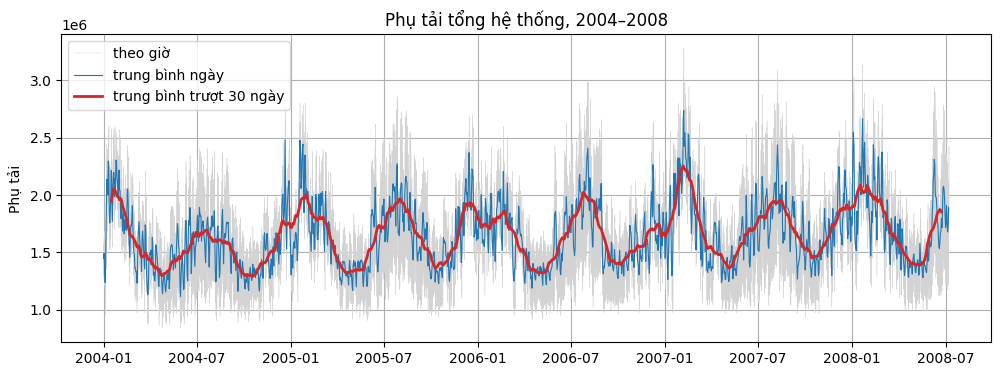

Đỉnh: 2007-02-06 07:00:00 | 3,280,423 | T_mean = 9.4°F
Đáy : 2004-04-25 03:00:00 | 836,900 | T_mean = 54.2°F


In [2]:
daily = s.resample("D").mean()                       # [M1] trung bình mỗi ngày
plt.plot(s, color="lightgray", linewidth=0.3, label="theo giờ")
plt.plot(daily, color="tab:blue", linewidth=0.8, label="trung bình ngày")
plt.plot(daily.rolling(30, center=True).mean(), color="tab:red", linewidth=2, label="trung bình trượt 30 ngày")
plt.title("Phụ tải tổng hệ thống, 2004–2008")
plt.ylabel("Phụ tải")
plt.legend()
plt.show()

# [M2] đỉnh và đáy
i_max, i_min = df["load"].idxmax(), df["load"].idxmin()
print("Đỉnh:", df.loc[i_max, "datetime"], f"| {df.loc[i_max, 'load']:,.0f} | T_mean = {df.loc[i_max, 'T_mean']:.1f}°F")
print("Đáy :", df.loc[i_min, "datetime"], f"| {df.loc[i_min, 'load']:,.0f} | T_mean = {df.loc[i_min, 'T_mean']:.1f}°F")

### Nhận xét

- Chuỗi có **mùa vụ năm rất rõ** với hai đỉnh mỗi năm (mùa đông và mùa hè) và hai đáy (xuân, thu).
- Đường trung bình trượt cho thấy mức phụ tải **tăng dần** theo các năm (phân tích kỹ ở mục 7).
- Đỉnh cao nhất rơi vào **sáng một ngày tháng 2/2007** khi nhiệt độ trung bình chỉ khoảng 9°F: phụ tải cao nhất đến từ cái **lạnh**, không phải cái nóng.

## 2. Chu kỳ ngày

### Lý thuyết

Phụ tải theo giờ trong ngày phản ánh nhịp sinh hoạt: thấp về đêm, tăng khi mọi người thức dậy và đi làm, có đỉnh khi kết hợp sinh hoạt gia đình buổi tối với sưởi hoặc điều hòa. Để so hình dạng giữa các nhóm có mức khác nhau, ta **chuẩn hóa** bằng cách chia cho trung bình chung (1,0 = mức trung bình).

### Mục đích

- **[M1]** Thấy hình dạng chu kỳ ngày của ngày thường và cuối tuần.
- **[M2]** Kiểm tra hình dạng đó có **thay đổi theo mùa** không. Nếu có, một mô hình chỉ có "chu kỳ ngày cố định" sẽ thiếu.

Tháng 1 (mùa đông): giờ đỉnh = 7:00, giờ đáy = 1:00
Tháng 7 (mùa hè): giờ đỉnh = 18:00, giờ đáy = 3:00


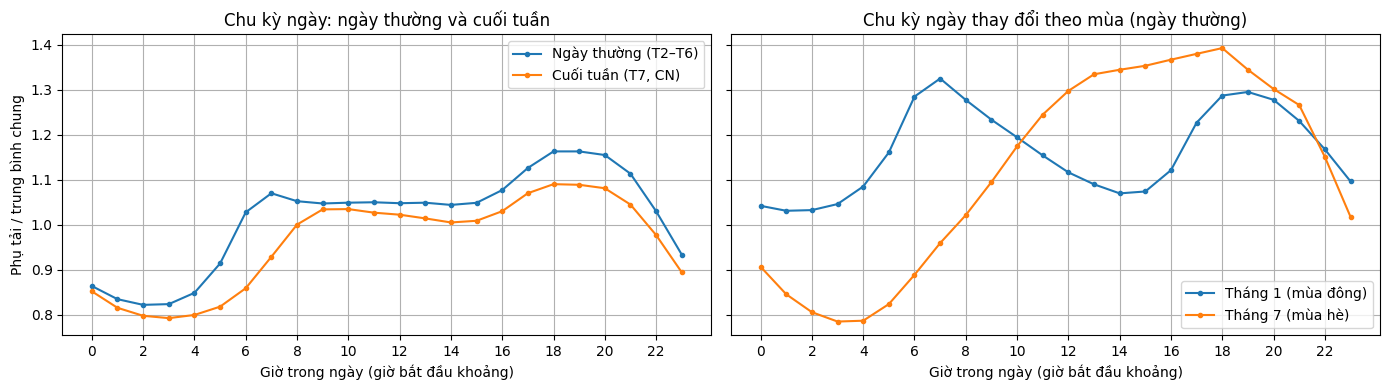

In [3]:
mean_all = df["load"].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

# [M1] Ngày thường và cuối tuần
for flag, name in [(False, "Ngày thường (T2–T6)"), (True, "Cuối tuần (T7, CN)")]:
    prof = df[df["is_weekend"] == flag].groupby("hour")["load"].mean() / mean_all
    axes[0].plot(prof, marker="o", markersize=3, label=name)
axes[0].set_title("Chu kỳ ngày: ngày thường và cuối tuần")

# [M2] Tháng 1 (mùa đông) và tháng 7 (mùa hè), chỉ ngày thường
for month, name in [(1, "Tháng 1 (mùa đông)"), (7, "Tháng 7 (mùa hè)")]:
    part = df[(df["month"] == month) & (~df["is_weekend"])]
    prof = part.groupby("hour")["load"].mean() / mean_all
    axes[1].plot(prof, marker="o", markersize=3, label=name)
    print(f"{name}: giờ đỉnh = {prof.idxmax()}:00, giờ đáy = {prof.idxmin()}:00")
axes[1].set_title("Chu kỳ ngày thay đổi theo mùa (ngày thường)")

for ax in axes:
    ax.set_xlabel("Giờ trong ngày (giờ bắt đầu khoảng)")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()
axes[0].set_ylabel("Phụ tải / trung bình chung")
plt.tight_layout()
plt.show()

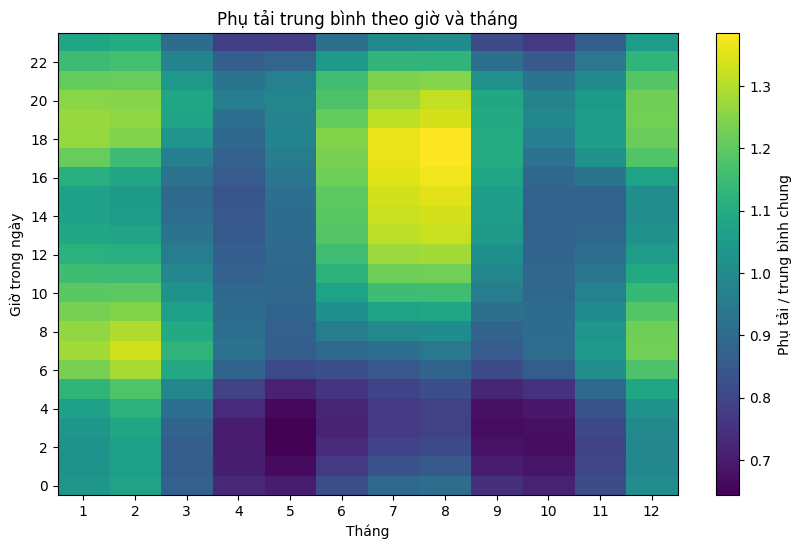

In [4]:
# [M2] Bản đồ nhiệt giờ x tháng: nhìn cùng lúc chu kỳ ngày và chu kỳ năm
heat = df.pivot_table(index="hour", columns="month", values="load", aggfunc="mean") / mean_all
plt.figure(figsize=(10, 6))
plt.imshow(heat, aspect="auto", cmap="viridis", origin="lower")
plt.colorbar(label="Phụ tải / trung bình chung")
plt.xticks(range(12), range(1, 13))
plt.yticks(range(0, 24, 2), range(0, 24, 2))
plt.xlabel("Tháng")
plt.ylabel("Giờ trong ngày")
plt.title("Phụ tải trung bình theo giờ và tháng")
plt.grid(False)
plt.show()

### Nhận xét

- Ngày thường: đáy khoảng **2–3 giờ sáng** (khoảng 0,82 lần trung bình), đỉnh **18–20 giờ** (khoảng 1,16 lần). Cuối tuần thấp hơn và buổi sáng tăng chậm hơn.
- **Hình dạng chu kỳ ngày đổi theo mùa:** mùa đông đỉnh vào **buổi sáng** (khoảng 7 giờ), mùa hè đỉnh vào **chiều tối** (khoảng 18 giờ). Bản đồ nhiệt cho thấy rõ hai "vùng nóng": sáng và tối mùa đông, chiều mùa hè.
- **Hệ quả cho mô hình:** một chu kỳ ngày cố định cả năm (ví dụ seasonal naive lag 24 dùng chung một khuôn) sẽ thiếu. Cần cho chu kỳ ngày **tương tác với mùa hoặc với nhiệt độ**. Đây là ví dụ cụ thể cho loại giả thuyết "chi tiết hóa" ở tầng 2 của ToT.

## 3. Chu kỳ tuần

### Lý thuyết

Phụ tải ngày thường cao hơn cuối tuần vì hoạt động sản xuất, văn phòng, trường học. Đây là lý do mô hình phụ tải thường có thêm chu kỳ 168 giờ (một tuần) bên cạnh chu kỳ 24 giờ.

### Mục đích

- **[M1]** Đo mức chênh lệch giữa các ngày trong tuần.

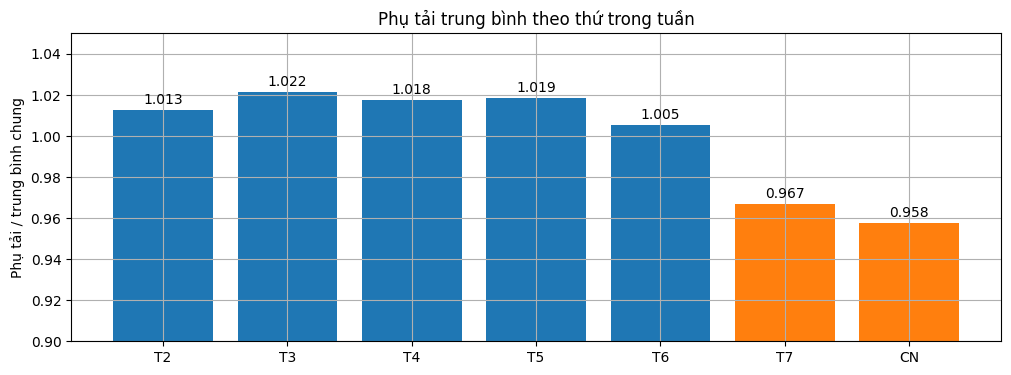

In [5]:
by_dow = df.groupby("dayofweek")["load"].mean() / mean_all     # [M1]
plt.bar(DAYS, by_dow, color=["tab:blue"] * 5 + ["tab:orange"] * 2)
plt.ylim(0.9, 1.05)
for i, v in enumerate(by_dow):
    plt.text(i, v + 0.003, f"{v:.3f}", ha="center")
plt.title("Phụ tải trung bình theo thứ trong tuần")
plt.ylabel("Phụ tải / trung bình chung")
plt.show()

### Nhận xét

- Thứ Hai đến thứ Sáu gần như bằng nhau (khoảng 1,01–1,02), thứ Sáu thấp hơn một chút.
- Thứ Bảy (khoảng 0,97) và Chủ nhật (khoảng 0,96) thấp hơn ngày thường khoảng **4–6%**.
- Chênh lệch theo tuần **nhỏ hơn nhiều** so với chênh lệch theo giờ trong ngày (±16%) hay theo tháng (mục 4).

## 4. Chu kỳ năm

### Lý thuyết

Chu kỳ năm của phụ tải chủ yếu do **thời tiết**: mùa đông cần sưởi, mùa hè cần làm mát. Ở vùng có cả mùa đông lạnh và mùa hè nóng, ta kỳ vọng **hai đỉnh** mỗi năm.

### Mục đích

- **[M1]** Kiểm tra số đỉnh và vị trí của chúng trong năm.

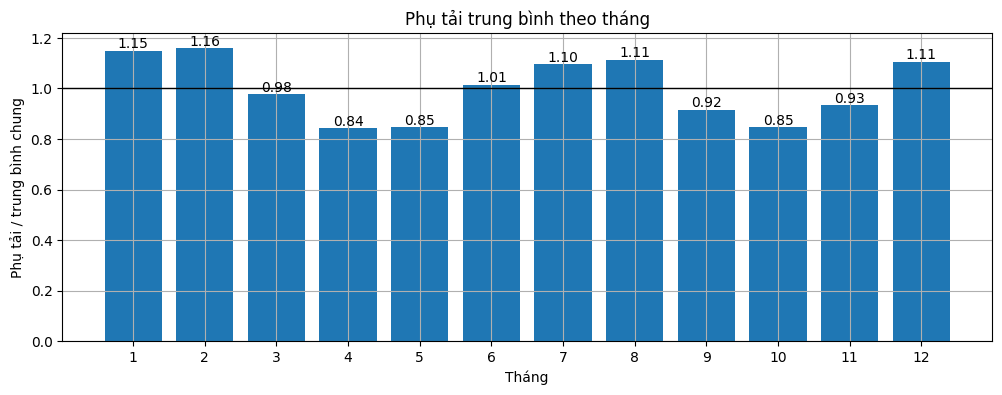

In [6]:
by_month = df.groupby("month")["load"].mean() / mean_all       # [M1]
plt.bar(range(1, 13), by_month, color="tab:blue")
plt.axhline(1, color="black", linewidth=1)
for m, v in by_month.items():
    plt.text(m, v + 0.01, f"{v:.2f}", ha="center")
plt.xticks(range(1, 13))
plt.xlabel("Tháng")
plt.ylabel("Phụ tải / trung bình chung")
plt.title("Phụ tải trung bình theo tháng")
plt.show()

### Nhận xét

- **Hai đỉnh:** mùa đông (tháng 1–2, khoảng 1,15–1,16) và mùa hè (tháng 7–8, khoảng 1,10–1,11).
- **Hai đáy:** mùa xuân (tháng 4–5) và mùa thu (tháng 10), khoảng 0,84–0,85.
- Biên độ theo tháng khoảng **±16%**, lớn hơn nhiều so với chu kỳ tuần.

## 5. Tự tương quan (ACF)

### Lý thuyết

**Hàm tự tương quan** (ACF) ở độ trễ k là hệ số tương quan giữa chuỗi và chính nó dịch đi k bước:

$$\rho(k) = \mathrm{Corr}(y_t,\, y_{t-k})$$

Nếu chuỗi có chu kỳ dài p, ACF sẽ có **đỉnh** tại k = p, 2p, … Với phụ tải theo giờ, ta kỳ vọng đỉnh ở 24 (ngày), 168 (tuần) và 8 760 (năm).

ACF cũng cho biết **seasonal naive** (dự báo bằng giá trị cùng giờ của chu kỳ trước) có triển vọng đến đâu: ACF ở độ trễ 24 càng cao, "giờ này hôm qua" càng là một dự báo tốt cho "giờ này hôm nay".

### Mục đích

- **[M1]** Xác nhận các chu kỳ bằng một thước đo định lượng, không chỉ bằng mắt.
- **[M2]** Đánh giá sơ bộ triển vọng của các baseline seasonal naive (lag 24, lag 168).

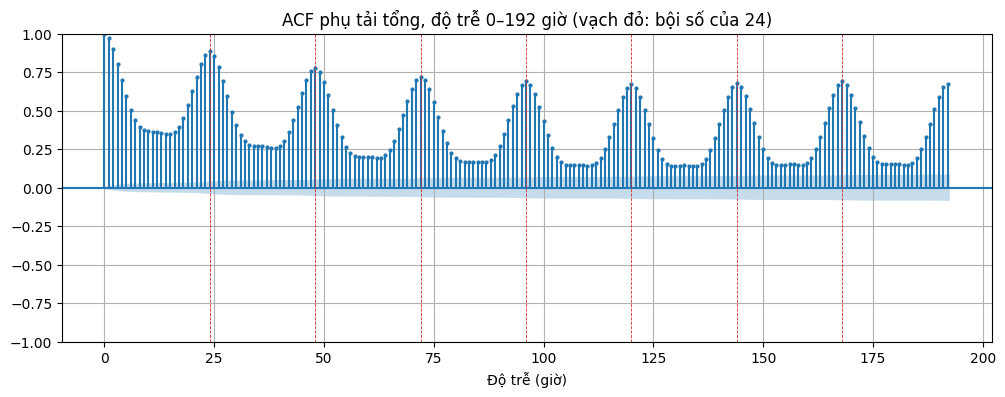

,ACF
độ trễ (giờ),
1,0.971
24,0.885
48,0.777
168,0.694
8760,0.651


In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(s, lags=24 * 8, ax=ax, markersize=2)          # [M1] 8 ngày đầu
for lag in [24, 48, 72, 96, 120, 144, 168]:
    ax.axvline(lag, color="tab:red", linewidth=0.6, linestyle="--")
ax.set_title("ACF phụ tải tổng, độ trễ 0–192 giờ (vạch đỏ: bội số của 24)")
ax.set_xlabel("Độ trễ (giờ)")
plt.show()

# [M2] Giá trị ACF ở các độ trễ quan trọng
acf_table = pd.Series({lag: s.autocorr(lag) for lag in [1, 24, 48, 168, 8760]}, name="ACF").round(3)
acf_table.index.name = "độ trễ (giờ)"
acf_table.to_frame()

### Nhận xét

- ACF có **đỉnh tại mọi bội số của 24**, và đỉnh ở **168** cao hơn các đỉnh 144, 120 xung quanh: có cả chu kỳ ngày lẫn chu kỳ tuần.
- ACF(1) = 0,971: giờ liền trước gần như quyết định giờ hiện tại, nhưng dự báo 24 giờ tới không dùng được thông tin này cho mọi giờ.
- ACF(24) = 0,885 > ACF(168) = 0,694: "giờ này hôm qua" giống "giờ này hôm nay" hơn "giờ này tuần trước". Một phần vì thời tiết hôm qua gần với hôm nay hơn tuần trước.
- ACF(8 760) = 0,651: cùng giờ năm trước vẫn còn tương quan khá, nhờ mùa vụ năm.

## 6. Quan hệ phụ tải – nhiệt độ

### Lý thuyết

**Hệ số tương quan Pearson** chỉ đo quan hệ **tuyến tính**. Nếu quan hệ thật là cong (ví dụ hình chữ U), Pearson có thể gần 0 dù hai biến liên hệ rất chặt. Vì vậy, ngoài Pearson, ta:
1. **Chia nhiệt độ thành khoảng** và tính phụ tải trung bình trong mỗi khoảng, để thấy hình dạng quan hệ.
2. Dùng **hệ số xác định R²** của hồi quy có đa thức nhiệt độ để đo nhiệt độ giải thích được bao nhiêu phần biến động.

Mô hình hồi quy dùng ở đây là phiên bản rút gọn của benchmark GEFCom2012:

$$\text{load}_t = \sum_{h=0}^{23}\beta_h\,\mathbb{1}[\text{giờ}_t = h] + \gamma_1 T_t + \gamma_2 T_t^2 + \gamma_3 T_t^3 + \varepsilon_t$$

So R² của mô hình **chỉ có giờ trong ngày** với mô hình **giờ + đa thức nhiệt độ** cho biết nhiệt độ bổ sung được bao nhiêu. Phép so này chỉ làm trên **giai đoạn train** (2004–2006).

### Mục đích

- **[M1]** Thấy hình dạng quan hệ phụ tải – nhiệt độ.
- **[M2]** Chỉ ra vì sao **tương quan tuyến tính gây hiểu nhầm** ở đây.
- **[M3]** Đo mức đóng góp của nhiệt độ bằng R² trên giai đoạn train.

Pearson(load, T_mean) trên toàn bộ dữ liệu = -0.115


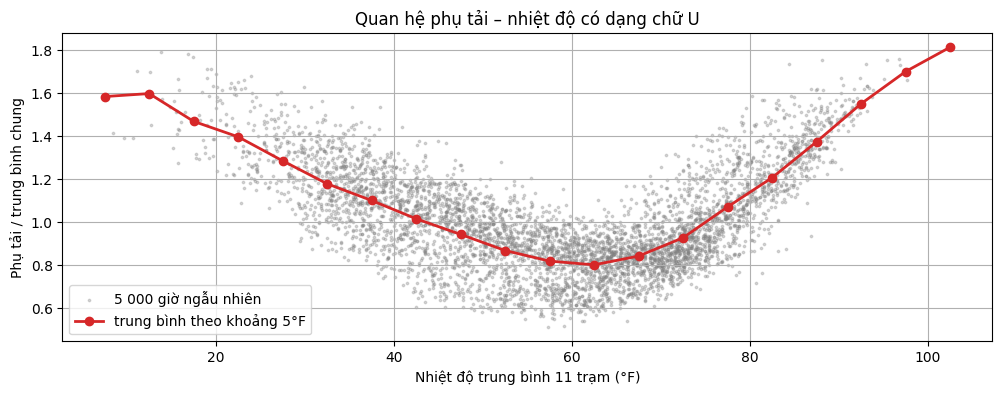

Phụ tải thấp nhất ở khoảng nhiệt độ: (60, 65] (°F)


In [8]:
# [M2] Tương quan tuyến tính
print(f"Pearson(load, T_mean) trên toàn bộ dữ liệu = {df['load'].corr(df['T_mean']):.3f}")

# [M1] Phụ tải trung bình theo khoảng nhiệt độ 5°F
bins = pd.cut(df["T_mean"], bins=range(0, 111, 5))
curve = df.groupby(bins, observed=True)["load"].mean() / mean_all
centers = [b.mid for b in curve.index]

sample = df.sample(5000, random_state=0)            # vẽ 5 000 điểm ngẫu nhiên cho đỡ rối
plt.scatter(sample["T_mean"], sample["load"] / mean_all, s=3, alpha=0.3, color="gray", label="5 000 giờ ngẫu nhiên")
plt.plot(centers, curve.values, color="tab:red", marker="o", linewidth=2, label="trung bình theo khoảng 5°F")
plt.xlabel("Nhiệt độ trung bình 11 trạm (°F)")
plt.ylabel("Phụ tải / trung bình chung")
plt.title("Quan hệ phụ tải – nhiệt độ có dạng chữ U")
plt.legend()
plt.show()

print(f"Phụ tải thấp nhất ở khoảng nhiệt độ: {curve.idxmin()} (°F)")

In [9]:
def r2_hour_poly(data, temp_col=None, degree=3):
    # R² của hồi quy: biến giả theo giờ (+ đa thức nhiệt độ nếu có temp_col), giải bằng bình phương tối thiểu
    X = pd.get_dummies(data["hour"], prefix="h", dtype=float)          # 24 cột giả, thay cho hệ số chặn
    if temp_col is not None:
        t = data[temp_col] / 100                                        # chia 100 để các lũy thừa không quá lớn
        for p in range(1, degree + 1):
            X[f"T^{p}"] = t ** p
    y = data["load"].to_numpy()
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
    resid = y - X.to_numpy() @ beta
    return 1 - resid.var() / y.var()

train = df[df["datetime"] <= TRAIN_END]                                  # [M3] chỉ giai đoạn train
print(f"R² chỉ có giờ trong ngày          : {r2_hour_poly(train):.3f}")
print(f"R² giờ + đa thức bậc 3 của T_mean : {r2_hour_poly(train, 'T_mean'):.3f}")

R² chỉ có giờ trong ngày          : 0.224
R² giờ + đa thức bậc 3 của T_mean : 0.827


### Nhận xét

- **Pearson ≈ −0,12**, gần như "không tương quan". Nếu chỉ nhìn con số này, ta sẽ kết luận sai rằng nhiệt độ không quan trọng.
- Thực tế quan hệ có **dạng chữ U** rõ rệt: phụ tải thấp nhất ở khoảng **60–65°F** (khoảng 16–18°C), tăng khi lạnh hơn (sưởi) và tăng **dốc hơn** khi nóng hơn (điều hòa). Ở hai đầu, phụ tải cao gấp khoảng 1,6–1,8 lần trung bình. Hai nhánh ngược chiều triệt tiêu nhau nên Pearson gần 0.
- Trên giai đoạn train, giờ trong ngày chỉ giải thích được khoảng **22%** biến động; thêm đa thức nhiệt độ tăng lên khoảng **83%**. **Nhiệt độ là biến giải thích mạnh nhất**, và phải đưa vào **dạng phi tuyến**.
- **Liên hệ với đề tài:** đây là ví dụ cụ thể vì sao thầy muốn **dữ liệu chấm điểm thay vì LLM**. Một bộ đánh giá chỉ dựa vào tương quan tuyến tính, hoặc vào "cảm giác" từ một con số, có thể loại nhầm giả thuyết đúng nhất.

## 7. Ngày lễ

### Lý thuyết

Ta kỳ vọng phụ tải ngày lễ **thấp hơn** ngày thường. Cách đo đơn giản: so phụ tải trung bình của ngày lễ với trung bình các **ngày thường không phải lễ** trong ±14 ngày xung quanh. Tỉ số < 1 nghĩa là ngày lễ thấp hơn.

Cách đo này có một điểm yếu: nó **không kiểm soát nhiệt độ**. Nếu ngày lễ rơi vào một đợt lạnh bất thường, phụ tải có thể cao hơn xung quanh dù nhu cầu sinh hoạt giảm. Hai hiệu ứng **trộn lẫn** vào nhau (*confounding*).

### Mục đích

- **[M1]** Đo hiệu ứng ngày lễ một cách đơn giản.
- **[M2]** Kiểm tra hiệu ứng có **ổn định** không, và nhiệt độ có làm nhiễu phép đo không.

count    45.000
mean      0.958
std       0.127
min       0.697
25%       0.856
50%       0.963
75%       1.043
max       1.325
Name: tỉ số so với ngày thường, dtype: float64


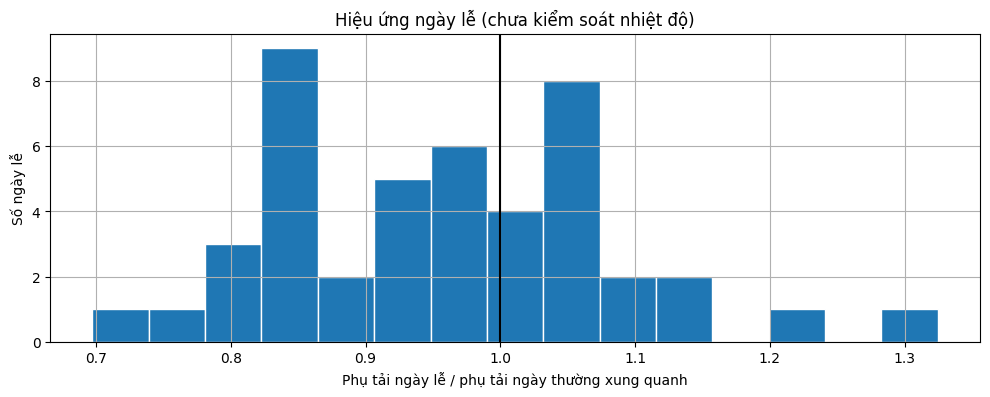

,ngày,thứ,tỉ số so với ngày thường,T ngày lễ (°F),T trung bình ngày thường (°F)
31,2007-01-15,T2,0.70,62.83,39.22
38,2007-11-22,T5,0.74,62.55,45.79
0,2004-01-01,T5,0.79,43.17,37.17
2,2004-02-16,T2,1.15,26.77,38.28
11,2005-01-17,T2,1.20,25.46,40.09
41,2008-01-21,T2,1.32,21.53,41.50


In [10]:
day = (df.set_index("datetime")
         .resample("D")
         .agg(load=("load", "mean"), T=("T_mean", "mean"),
              is_holiday=("is_holiday", "max"), dayofweek=("dayofweek", "first")))

rows = []
for date, r in day[day["is_holiday"]].iterrows():
    near = day[(day.index >= date - pd.Timedelta(14, unit="D")) & (day.index <= date + pd.Timedelta(14, unit="D"))
               & (~day["is_holiday"]) & (day["dayofweek"] < 5)]        # ngày thường, không lễ, ±14 ngày
    rows.append({"ngày": date.date(), "thứ": DAYS[int(r["dayofweek"])],
                 "tỉ số so với ngày thường": r["load"] / near["load"].mean(),   # [M1]
                 "T ngày lễ (°F)": r["T"], "T trung bình ngày thường (°F)": near["T"].mean()})
hol = pd.DataFrame(rows)

print(hol["tỉ số so với ngày thường"].describe().round(3))                  # [M2] ổn định không?
plt.hist(hol["tỉ số so với ngày thường"], bins=15, color="tab:blue", edgecolor="white")
plt.axvline(1, color="black")
plt.xlabel("Phụ tải ngày lễ / phụ tải ngày thường xung quanh")
plt.ylabel("Số ngày lễ")
plt.title("Hiệu ứng ngày lễ (chưa kiểm soát nhiệt độ)")
plt.show()

# [M2] Các trường hợp cực trị và nhiệt độ tương ứng
hol.sort_values("tỉ số so với ngày thường").round(2).iloc[[0, 1, 2, -3, -2, -1]]

### Nhận xét

- Trung vị tỉ số khoảng **0,96**: ngày lễ nhìn chung thấp hơn ngày thường xung quanh vài phần trăm, đúng kỳ vọng.
- Nhưng **độ phân tán rất lớn**, từ khoảng 0,70 đến 1,33, và nhiệt độ giải thích được các trường hợp cực trị:
  - Ba ngày lễ có tỉ số **cao nhất** (16/02/2004, 17/01/2005, 21/01/2008) đều là ngày lễ mùa đông **lạnh hơn** các ngày so sánh khoảng 11–20°F. Đợt lạnh làm tăng nhu cầu sưởi, che mất hiệu ứng "nghỉ lễ".
  - Ngày có tỉ số **thấp nhất** (15/01/2007) thì ngược lại: **ấm bất thường** (khoảng 63°F so với 39°F của các ngày so sánh), nên phụ tải thấp do vừa nghỉ lễ vừa ít cần sưởi.
- **Kết luận:** hiệu ứng ngày lễ **có thật nhưng không đo được tách bạch** bằng phép so đơn giản. Phải ước lượng **đồng thời với nhiệt độ** trong mô hình. Câu "ngày lễ giống Chủ nhật" là một **giả thuyết cần dữ liệu kiểm chứng**, không phải điều hiển nhiên. Đây đúng là loại giả thuyết ToT nên đề xuất và để backtest phán xét.

## 8. Xu hướng dài hạn

### Lý thuyết

So trung bình **cả năm** giữa các năm là không công bằng, vì năm 2008 chỉ có dữ liệu đến tháng 7 (gồm mùa đông nhưng thiếu mùa hè và mùa thu). Để so công bằng, chỉ so **cùng một khoảng tháng** của mọi năm: tháng 1 đến tháng 6.

### Mục đích

- **[M1]** Ước lượng mức tăng trưởng phụ tải qua các năm, so sánh công bằng.

In [11]:
h1 = df[df["month"] <= 6].groupby("year")["load"].mean()       # [M1] cùng khoảng tháng 1-6
growth = (h1 / h1.iloc[0] - 1) * 100
pd.DataFrame({"trung bình T1–T6": h1.round(0), "so với 2004 (%)": growth.round(1)})

,trung bình T1–T6,so với 2004 (%)
year,,
2004,1580919.0,0.0
2005,1611235.0,1.9
2006,1585649.0,0.3
2007,1712333.0,8.3
2008,1736807.0,9.9


### Nhận xét

- Trung bình tháng 1–6 tăng khoảng **10%** từ 2004 đến 2008, nhưng **không đều**: 2005 tăng khoảng 2%, 2006 lại thấp hơn 2005 (gần bằng 2004), còn 2007 tăng vọt khoảng 8%. Một phần dao động giữa các năm có thể do thời tiết; cần mô hình có nhiệt độ mới tách được xu hướng thật.
- **Hệ quả:** mô hình nên có cách xử lý **mức thay đổi theo thời gian**: biến xu hướng, hoặc ưu tiên dữ liệu gần đây (cửa sổ huấn luyện ngắn). Một phần mức tăng năm 2008 đến từ **zone 10** (mục 9).

## 9. Các zone bất thường

### Lý thuyết

Chuỗi tổng là tổng của 20 zone. Một bất thường ở cấp zone (dữ liệu trùng, thay đổi đột ngột) có thể làm sai lệch chuỗi tổng hoặc ảnh hưởng đến lựa chọn chuỗi mục tiêu. Ba điều cần kiểm tra:
1. Có zone nào **trùng nhau hoàn toàn** không (dấu hiệu lỗi dữ liệu hoặc hai zone dùng chung đồng hồ đo)?
2. Có zone nào **quá nhỏ** để có ý nghĩa không?
3. Có zone nào **đổi mức đột ngột** (*thay đổi chế độ*, regime change) không?

### Mục đích

- **[M1]** Phát hiện zone trùng nhau.
- **[M2]** Phát hiện zone có tỉ trọng không đáng kể.
- **[M3]** Phát hiện thay đổi chế độ và đo ảnh hưởng của nó lên chuỗi tổng.

In [12]:
W = zones.pivot(index="datetime", columns="zone_id", values="load")   # mỗi zone một cột
total = W.sum(axis=1)

# [M1] Cặp zone trùng nhau ở MỌI giờ
dups = [(a, b) for a in W.columns for b in W.columns if a < b and W[a].equals(W[b])]
print("Các cặp zone trùng nhau hoàn toàn:", dups)

# [M2] Tỉ trọng trung bình của mỗi zone trong tổng
share = (W.div(total, axis=0).mean() * 100).sort_values()
print("\n3 zone nhỏ nhất (% tổng):")
print(share.head(3).round(3))

Các cặp zone trùng nhau hoàn toàn: [(3, 7)]

3 zone nhỏ nhất (% tổng):
zone_id
4    0.031
8    0.228
5    0.463
dtype: float64


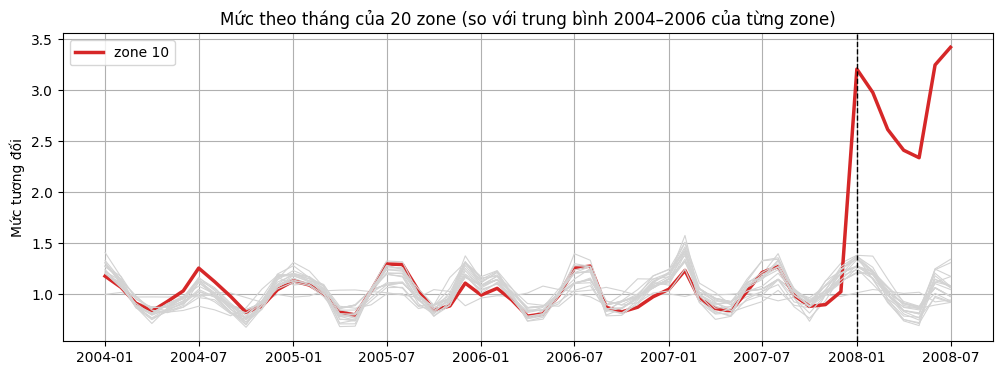

Tỉ trọng zone 10 trong tổng: năm 2007 = 1.6%, năm 2008 = 4.4%
Mức zone 10 theo tháng quanh điểm gãy:
datetime
2007-10-01    23692.0
2007-11-01    24146.0
2007-12-01    27556.0
2008-01-01    86301.0
2008-02-01    80114.0
2008-03-01    70358.0
Freq: MS, Name: 10, dtype: float64


In [13]:
# [M3] Mức trung bình theo tháng của từng zone, chia cho mức trung bình năm 2004-2006 của chính zone đó
monthly = W.resample("MS").mean()
rel = monthly / monthly.loc[:"2006-12"].mean()

for z in W.columns:
    style = dict(color="tab:red", linewidth=2.5, label="zone 10") if z == 10 else dict(color="lightgray", linewidth=0.8)
    plt.plot(rel.index, rel[z], **style)
plt.axvline(pd.Timestamp("2008-01-01"), color="black", linestyle="--", linewidth=1)
plt.title("Mức theo tháng của 20 zone (so với trung bình 2004–2006 của từng zone)")
plt.ylabel("Mức tương đối")
plt.legend()
plt.show()

z10_share = W[10] / total
print(f"Tỉ trọng zone 10 trong tổng: năm 2007 = {z10_share[W.index.year == 2007].mean():.1%}, "
      f"năm 2008 = {z10_share[W.index.year == 2008].mean():.1%}")
print("Mức zone 10 theo tháng quanh điểm gãy:")
print(monthly.loc["2007-10":"2008-03", 10].round(0))

### Nhận xét

- **Zone 3 và zone 7 trùng nhau ở mọi giờ.** Có thể là lỗi dữ liệu của cuộc thi, hoặc hai zone dùng chung một nguồn đo. Tổng hệ thống **chính thức** (zone 21) vẫn cộng cả hai, nên ta giữ nguyên để đúng định nghĩa. Nếu sau này dự báo theo zone, chỉ cần mô hình hóa một trong hai.
- **Zone 4 rất nhỏ** (khoảng 0,03% tổng), không ảnh hưởng đến chuỗi tổng.
- **Zone 10 đổi chế độ đột ngột từ tháng 1/2008**: mức tăng khoảng **gấp 3** (từ khoảng 27,6 nghìn tháng 12/2007 lên 86,3 nghìn tháng 1/2008) và duy trì ở mức cao hơn hẳn các năm trước. Tỉ trọng của zone 10 trong tổng tăng từ khoảng 1,6% (2007) lên khoảng 4,4% (2008).
- **Hệ quả cho đánh giá:** năm 2008 (dự kiến là tập test) chứa một thay đổi chế độ thật ở cấp zone, làm chuỗi tổng tăng thêm khoảng 2–3 điểm phần trăm. Đây là tình huống tốt để kiểm tra giả thuyết "chuỗi vừa thay đổi chế độ" của ToT, và cũng là lời nhắc: mô hình chỉ học từ dữ liệu cũ có thể dự báo thấp trong 2008.

## 10. Chốt lựa chọn dữ liệu (mục 2.11)

### 10.1 Chọn nhiệt độ: trạm nào?

#### Lý thuyết

Đề bài không cho biết trạm nào ứng với vùng nào, nên phải chọn bằng dữ liệu. Tiêu chí: trạm nào giúp **giải thích phụ tải tốt nhất**, đo bằng R² của mô hình giờ + đa thức bậc 3 ở mục 6. Các phương án:
- **Một trạm tốt nhất.**
- **Trung bình vài trạm tốt nhất.**
- **Trung bình cả 11 trạm** (`T_mean`).

**Chống rò rỉ:** việc chọn **chỉ dùng giai đoạn train**. Nếu chọn trạm dựa trên cả năm 2008 rồi đánh giá trên 2008, kết quả test sẽ lạc quan một cách giả tạo.

Một lưu ý khác: chọn "trạm tốt nhất" cũng là một lần **chọn trong nhiều phương án**, nên có rủi ro chọn trúng nhờ may mắn. Nếu lợi ích nhỏ, phương án **đơn giản và không cần chọn** (trung bình tất cả) đáng tin hơn.

#### Mục đích

- **[M1]** So sánh khả năng giải thích của từng trạm, của trung bình 3 trạm tốt nhất, và của trung bình 11 trạm, chỉ trên giai đoạn train.
- **[M2]** Chọn một phương án dùng mặc định cho các giai đoạn sau.

R² trên giai đoạn train (giờ + đa thức bậc 3):
T_mean    0.8270
T7        0.8141
T9        0.8091
T3        0.8081
T5        0.7963
T10       0.7862
T6        0.7849
T2        0.7830
T11       0.7770
T1        0.7627
T4        0.7609
T8        0.7535

Trung bình 3 trạm tốt nhất ['T7', 'T9', 'T3']: R² = 0.8313


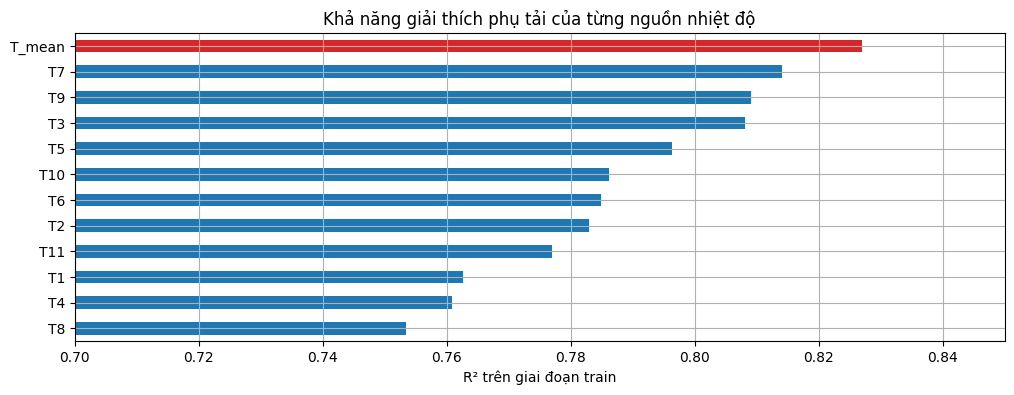

In [14]:
# [M1] R² từng trạm trên giai đoạn train
stations = [f"T{i}" for i in range(1, 12)]
r2 = pd.Series({col: r2_hour_poly(train, col) for col in stations + ["T_mean"]}).sort_values(ascending=False)

top3 = [c for c in r2.index if c != "T_mean"][:3]
train_top3 = train.assign(T_top3=train[top3].mean(axis=1))
r2_top3 = r2_hour_poly(train_top3, "T_top3")

print("R² trên giai đoạn train (giờ + đa thức bậc 3):")
print(r2.round(4).to_string())
print(f"\nTrung bình 3 trạm tốt nhất {top3}: R² = {r2_top3:.4f}")

r2.plot(kind="barh", color=["tab:red" if c == "T_mean" else "tab:blue" for c in r2.index])
plt.xlim(0.7, 0.85)
plt.xlabel("R² trên giai đoạn train")
plt.title("Khả năng giải thích phụ tải của từng nguồn nhiệt độ")
plt.gca().invert_yaxis()
plt.show()

#### Nhận xét và quyết định

- `T_mean` (trung bình 11 trạm) có R² khoảng **0,827**, **cao hơn mọi trạm đơn lẻ** (tốt nhất là T7, khoảng 0,814).
- Trung bình 3 trạm tốt nhất chỉ nhỉnh hơn `T_mean` khoảng **0,004**, một mức chênh nhỏ so với rủi ro "chọn trúng nhờ may mắn".
- Lý do trung bình tốt hơn từng trạm: phụ tải tổng là tổng của cả vùng, nên nhiệt độ đại diện cho **cả vùng** khớp hơn nhiệt độ một điểm; lấy trung bình cũng làm giảm sai số đo của từng trạm.

**[M2] Quyết định:** dùng **`T_mean`** làm biến nhiệt độ mặc định. Giữ `T1`…`T11` trong bảng tổng để có thể thử nghiệm sau (ví dụ một thought của ToT đề xuất dùng nhiệt độ theo trạm).

### 10.2 Chọn chuỗi mục tiêu

#### Lý thuyết và các phương án

| Phương án | Ưu điểm | Nhược điểm |
|---|---|---|
| **Tổng hệ thống** | Là mục tiêu chính thức của cuộc thi (trọng số cao nhất); chuỗi mượt, ít nhiễu; bất thường của một zone bị pha loãng; khớp tự nhiên với `T_mean` | Không khai thác được cấu trúc phân cấp zone |
| Một vài zone | Kiểm tra độ vững trên nhiều chuỗi khác nhau | Nhiều nhiễu; phải chọn trạm cho từng zone; zone 10 đổi chế độ |
| Cả 20 zone, gộp lên tổng | Đúng cấu trúc "chia → giải → gộp" của GoT | Chi phí gấp 20 lần; phức tạp ngay từ đầu |

#### Quyết định

1. **Chuỗi mục tiêu chính: phụ tải tổng hệ thống** (`load` trong bảng tổng).
2. **Dữ liệu zone được giữ lại** (`load_zones.parquet`) cho hai mục đích sau này: kiểm tra độ vững trên vài zone (mục 7.4) và hướng mở rộng GoT theo cấu trúc zone → tổng.
3. **18 giờ được lấp** (`is_imputed = True`) chỉ dùng làm đầu vào, **không dùng để chấm điểm**.
4. **Cần ghi nhớ khi đánh giá:** năm 2008 có thay đổi chế độ ở zone 10, và nhiệt độ được dùng ở dạng ex-post.

## 11. Tổng kết Giai đoạn 2

### Các đặc điểm chính của chuỗi phụ tải tổng

| Đặc điểm | Bằng chứng | Gợi ý cho mô hình / giả thuyết |
|---|---|---|
| Chu kỳ ngày | ACF(24) = 0,885; đáy 2–3 giờ, đỉnh 17–20 giờ | Seasonal naive lag 24; mùa vụ s = 24 |
| Chu kỳ ngày **đổi theo mùa** | Đỉnh sáng mùa đông, đỉnh chiều mùa hè | Tương tác giờ × mùa hoặc giờ × nhiệt độ |
| Chu kỳ tuần | ACF(168) = 0,694; cuối tuần thấp hơn 4–6% | Lag 168; biến thứ trong tuần |
| Chu kỳ năm | Hai đỉnh (đông, hè), hai đáy (xuân, thu) | Fourier theo năm; biến tháng |
| Nhiệt độ | Dạng chữ U, đáy ở 60–65°F; R² tăng từ 0,22 lên 0,83 | Đa thức nhiệt độ; mô hình cây |
| Ngày lễ | Trung vị thấp hơn khoảng 4%, nhưng bị nhiệt độ làm nhiễu | Biến ngày lễ, ước lượng đồng thời với nhiệt độ |
| Xu hướng | Tháng 1–6 tăng khoảng 10% từ 2004 đến 2008, không đều | Biến xu hướng; cửa sổ huấn luyện gần đây |
| Thay đổi chế độ | Zone 10 gấp khoảng 3 lần từ tháng 1/2008 | Huấn luyện lại trên dữ liệu sau điểm gãy |

### Các file của Giai đoạn 2

| File | Nội dung |
|---|---|
| `data/processed/load_zones.parquet` | 20 zone theo giờ, có cờ `is_imputed` |
| `data/processed/load_system.parquet` | Chuỗi tổng theo giờ |
| `data/processed/master_system.parquet` | Bảng tổng: phụ tải + nhiệt độ + lịch (39 600 × 22) |
| `src/data.py` | Module xử lý dữ liệu, điểm vào `load_dataset()` |

### Bước tiếp theo: Giai đoạn 3 (giao thức đánh giá)

Chốt cách chia train/validation/test theo thời gian, thiết lập rolling-origin cho dự báo 24 giờ, chọn các thước đo sai số, và viết hàm `similar_periods(origin)` để tìm "giai đoạn lịch sử tương tự", nền tảng cho bộ chấm điểm của ToT.